# import important libraries

In [35]:
from tensorflow.keras.datasets import mnist

# # Loading the training and test set, and checking the shape of each

In [36]:

(X_train,y_train),(X_test,y_test) = mnist.load_data()
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(60000, 28, 28)
(10000, 28, 28)
(60000,)
(10000,)


In [37]:
# Just visualising the data of y_train which contains the number of classes in other digits (0 to 9)to be identified
y_train[:7]

array([5, 0, 4, 1, 9, 2, 1], dtype=uint8)

In [38]:
# Just visualising the data of X_train which is in the form of 2D array, each array element showing pixel intensity from 0 to 255

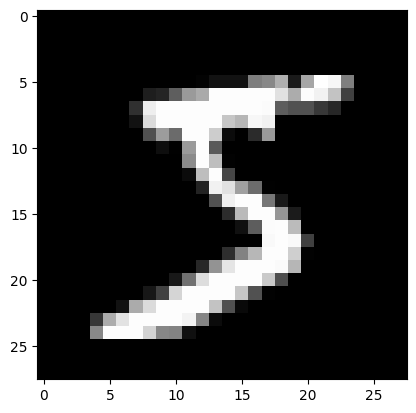

In [39]:
# Just visualising the data of X_train
import matplotlib.pyplot as plt
plt.imshow(X_train[0],cmap='gray')

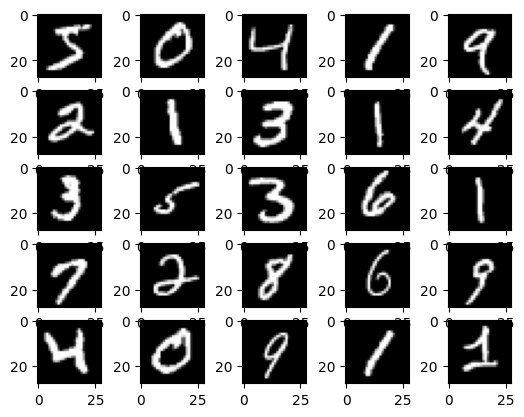

In [40]:
# Just visualising the data of X_train first 25 images using for loop
for i in range(25):
  plt.subplot(5,5,i+1)
  plt.imshow(X_train[i],cmap='gray')

# Preparing data for Artificial Neural Network (ANN) (which needs 1D data vector or 1D array), so reshape the data using reshape fn

In [41]:
X_train=X_train.reshape(len(X_train),28*28)
X_test=X_test.reshape( (X_test.shape[0]),28*28)

In [42]:
## Check shape after using reshape
X_train.shape
X_test.shape

(10000, 784)

In [43]:
# normalize the images in between 0 and 1
X_train=X_train/255
X_test=X_test/255

In [44]:
X_train[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

# Importing model and layer

In [45]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Defining the model architecture of ANN

In [46]:
model=Sequential()
model.add(Dense(100,activation='relu', input_shape=(784,)))
model.add(Dense(64,activation='relu'))
model.add(Dense(32, activation='relu'))

# output layer
model.add(Dense(10,activation='softmax'))

# Creating the model summary

In [47]:
#print the summary of the model
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_4 (Dense)             (None, 100)               78500     
                                                                 
 dense_5 (Dense)             (None, 64)                6464      
                                                                 
 dense_6 (Dense)             (None, 32)                2080      
                                                                 
 dense_7 (Dense)             (None, 10)                330       
                                                                 
Total params: 87374 (341.30 KB)
Trainable params: 87374 (341.30 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [48]:
# Param check shown in summary using self calcualtion for each dense layer
784*100+100

78500

In [49]:
64*100+64

6464

In [50]:
32*64+32

2080

In [51]:
32*10+10

330

In [52]:
78500+6464+2080+330

87374

# Compiling the model

In [53]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [54]:
batch_size=128
epochs=10

# Fit the model using training and testing data

In [55]:
history=model.fit(X_train,y_train,batch_size=batch_size,epochs=epochs,validation_data=(X_test,y_test))

Epoch 1/10
469/469 [==============================] - 3s 6ms/step - loss: 0.3501 - accuracy: 0.8984 - val_loss: 0.1549 - val_accuracy: 0.9543
Epoch 2/10
469/469 [==============================] - 3s 6ms/step - loss: 0.1376 - accuracy: 0.9596 - val_loss: 0.1203 - val_accuracy: 0.9627
Epoch 3/10
469/469 [==============================] - 3s 6ms/step - loss: 0.0991 - accuracy: 0.9711 - val_loss: 0.0995 - val_accuracy: 0.9695
Epoch 4/10
469/469 [==============================] - 2s 5ms/step - loss: 0.0778 - accuracy: 0.9766 - val_loss: 0.0880 - val_accuracy: 0.9729
Epoch 5/10
469/469 [==============================] - 2s 5ms/step - loss: 0.0630 - accuracy: 0.9805 - val_loss: 0.0952 - val_accuracy: 0.9709
Epoch 6/10
469/469 [==============================] - 2s 5ms/step - loss: 0.0521 - accuracy: 0.9844 - val_loss: 0.0843 - val_accuracy: 0.9735
Epoch 7/10
469/469 [==============================] - 2s 5ms/step - loss: 0.0431 - accuracy: 0.9864 - val_loss: 0.0821 - val_accuracy: 0.9767
Epoch 

In [56]:
# Since each epoch shows 469 which is total divided by batch size, self calculation
60000/128

468.75

# final accuracy

In [57]:
score = model.evaluate(X_test,y_test)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

313/313 [==============================] - 1s 2ms/step - loss: 0.0919 - accuracy: 0.9757
Test loss: 0.09191445261240005
Test accuracy: 0.9757000207901001


# Plot the accuracy and loss

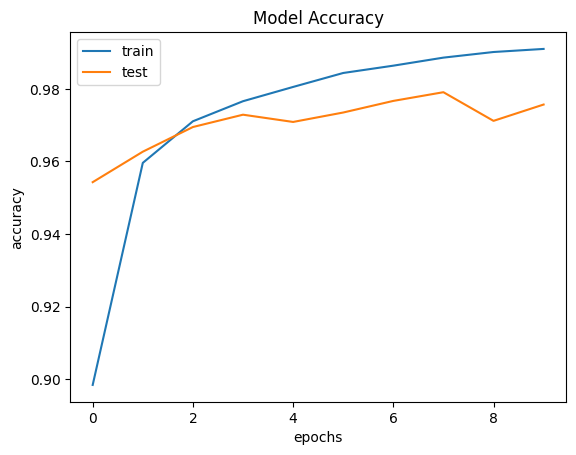

In [58]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epochs')
plt.legend(['train', 'test'], loc='best')
plt.show()

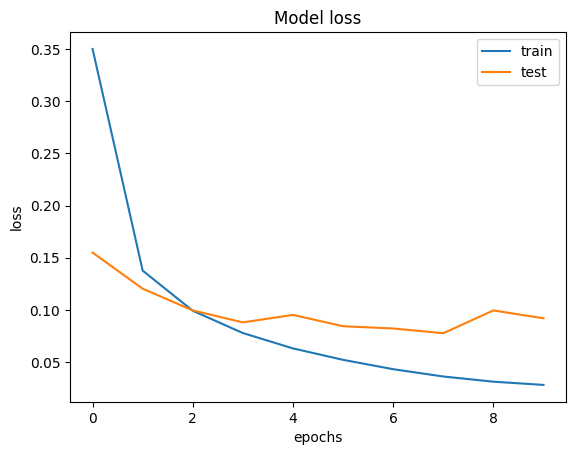

In [59]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('loss')
plt.xlabel('epochs')
plt.legend(['train', 'test'], loc='best')
plt.show()

# Prediction using model

In [60]:
y_pred=model.predict(X_test)

313/313 [==============================] - 1s 2ms/step


In [61]:
y_pred[0]

array([7.6849274e-09, 1.0586328e-09, 7.0971146e-07, 3.1964987e-07,
       2.0331729e-11, 4.1777820e-10, 1.2372445e-13, 9.9999887e-01,
       3.2285445e-09, 9.3484136e-09], dtype=float32)

# y pred[0] shows the probabilities of each class. The highest probability shows the digit to be predicted

# Numpy function argmax tells the position/location of largest numbers

In [62]:
import numpy as np

In [63]:
output=np.argmax(y_pred[0])
output

7

# Labels for test data

In [64]:
y_predict =np.argmax(y_pred, axis = 1)

In [65]:
y_predict[:5]

array([7, 2, 1, 0, 4])

# # Since first no in y_predict is 7, it is correct prediction

# Now building the confusion matrix for same

In [66]:
from sklearn.metrics import confusion_matrix
matrix =confusion_matrix(y_test,y_predict)
print("The confusion matrix is given as", matrix)

The confusion matrix is given as [[ 968    0    1    2    0    3    4    1    1    0]
 [   0 1123    0    1    0    1    2    1    7    0]
 [   3    1 1008    5    2    0    3    7    3    0]
 [   1    1    5  985    0    9    0    7    2    0]
 [   2    1    2    0  960    1    9    1    2    4]
 [   2    1    0   10    2  870    3    0    3    1]
 [   1    2    0    1    2   10  941    0    1    0]
 [   0    2    6    0    0    0    0 1016    2    2]
 [   2    0    1    8    5    9    3    8  935    3]
 [   3    6    0    8   12   10    0   15    4  951]]
